<a href="https://colab.research.google.com/github/msolanki0709/manish_solanki_nic/blob/main/Excercise4_Manish_Solanki.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Columns: ['ProductName', 'Price', 'Rate', 'Review', 'Summary']

Aggregated 'items' DataFrame (Top 10 Products):


,ProductName,mean_rating,mean_price
0,1170-BL-BR Unique New Day & Date Analog Watch ...,3.99,299.0
1,38024PP25 Minimalists Analog Watch - For Men,4.89,850.0
2,"3D METRO SUPER STORE JUICER_Gduumy 1 Juicer,1 ...",3.67,417.0
3,3D METRO SUPER STORE METRO_MIXER Pro 0 Juicer ...,4.75,199.0
4,77085PP03 Volt Analog Watch - For Men,4.71,699.0
5,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.69,219.0
6,@Home by nilkamal Walton Engineered Wood TV En...,4.44,11999.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.80,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.52,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.46,279.0


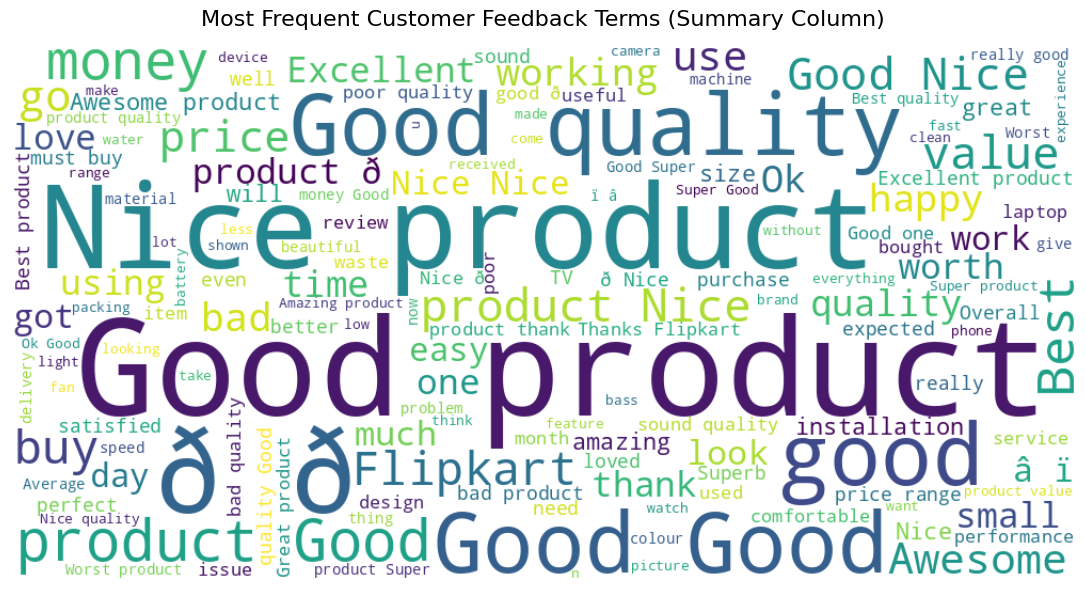

In [4]:
# Prerequisite: pip install pandas matplotlib wordcloud

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# 1. Load the Flipkart Product Customer Reviews Dataset
# Update the filename to match the exact CSV downloaded from Kaggle
file_path = '/content/flipkart_product.csv'
df = pd.read_csv(file_path, encoding='latin1', on_bad_lines='skip')

print("Original Columns:", df.columns.tolist())

# Standardize column names dynamically in case of minor Kaggle version differences
# Common Kaggle Flipkart dataset columns: 'productname', 'price', 'rate', 'review', 'summary'
col_map = {col.lower().replace("_", "").strip(): col for col in df.columns}
product_col = col_map.get('productname', 'ProductName')
price_col = col_map.get('price', 'Price')
rating_col = col_map.get('rate', 'Rate')
summary_col = col_map.get('summary', 'Summary')

# Clean 'price' column: remove currency symbols/commas and convert to numeric
df[price_col] = (
    df[price_col]
    .astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)
df[price_col] = pd.to_numeric(df[price_col], errors='coerce')

# Clean 'rating' column: convert to numeric and keep valid ratings (1 to 5)
df[rating_col] = pd.to_numeric(df[rating_col], errors='coerce')
df.loc[(df[rating_col] < 1) | (df[rating_col] > 5), rating_col] = None

# Drop rows missing essential product, price, or rating values
df_clean = df.dropna(subset=[product_col, price_col, rating_col]).copy()

# 2. Group by product name, calculate mean rating and mean price, store in 'items'
items = (
    df_clean.groupby(product_col, as_index=False)
    .agg(
        mean_rating=(rating_col, 'mean'),
        mean_price=(price_col, 'mean')
    )
    .round({'mean_rating': 2, 'mean_price': 2})
)

print("\nAggregated 'items' DataFrame (Top 10 Products):")
display(items.head(10))

# 3. Generate and display a Word Cloud from the 'Summary' column
summary_text = " ".join(df[summary_col].dropna().astype(str))

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=STOPWORDS,
    colormap='viridis',
    max_words=150
).generate(summary_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Customer Feedback Terms (Summary Column)', fontsize=16, pad=15)
plt.tight_layout()
plt.show()